In [1]:

import numpy as np
import pandas as pd


def generate_usm_dataset(n=500, seed=42):
    rng = np.random.default_rng(seed)

    # Latent operating-condition variable
    operating_load = rng.normal(0, 1, n)

    # Amplitude in micrometers
    amplitude = (
        25 + 5 * operating_load
        + rng.normal(0, 2, n)
    )

    amplitude = np.clip(amplitude, 10, 40)

    # Frequency in Hz
    frequency = (
        21000 + 900 * operating_load
        + rng.normal(0, 600, n)
    )

    frequency = np.clip(frequency, 18000, 25000)

    # Convert amplitude from micrometers to meters
    amplitude_m = amplitude * 1e-6

    # Calculate theoretical RMS acceleration
    vibration = (
        amplitude_m * (2 * np.pi * frequency) ** 2
        / np.sqrt(2)
    )

    # Add measurement variation
    vibration *= rng.normal(1, 0.04, n)
    vibration += rng.normal(0, 3, n)

    # Cutting force in Newtons
    cutting_force = (
        15
        + 3.5 * operating_load
        + 0.15 * (amplitude - 25)
        + rng.normal(0, 2, n)
    )

    cutting_force = np.clip(cutting_force, 5, 30)

    # Create dataframe
    df = pd.DataFrame({
        "Vibration": vibration,
        "Cutting Force": cutting_force,
        "Frequency": frequency,
        "Amplitude": amplitude
    })

    return df


# Generate dataset
df = generate_usm_dataset(n=500)

# Save dataset
df.to_csv("ultrasonic_machining.csv", index=False)

print(df.head())
print(df.describe())


       Vibration  Cutting Force     Frequency  Amplitude
0  359991.802241      17.810360  21238.675784  29.251310
1  226358.823262      11.346450  19626.442143  21.590449
2  368606.210098      19.990910  21426.722237  27.313296
3  373059.006494      19.515556  22226.854471  26.697817
4  102519.827750       8.356827  19245.864305  10.000000
           Vibration  Cutting Force     Frequency   Amplitude
count     500.000000     500.000000    500.000000  500.000000
mean   309025.693649      15.083215  20987.247210   24.845187
std     90897.166357       4.459008   1080.468464    5.189786
min    102519.827750       5.000000  18000.000000   10.000000
25%    245243.917398      11.996967  20292.698492   21.297751
50%    306896.698957      15.052725  20987.170416   25.219875
75%    363979.913444      18.146879  21668.498616   28.074294
max    656656.060344      30.000000  24361.417962   40.000000


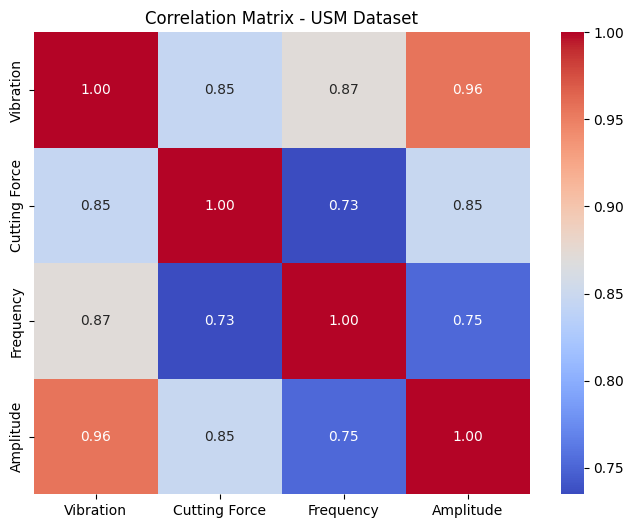

In [2]:
import seaborn as sns
import matplotlib.pyplot as plt

plt.figure(figsize=(8, 6))

sns.heatmap(
    df.corr(),
    annot=True,
    cmap="coolwarm",
    fmt=".2f"
)

plt.title("Correlation Matrix - USM Dataset")
plt.show()

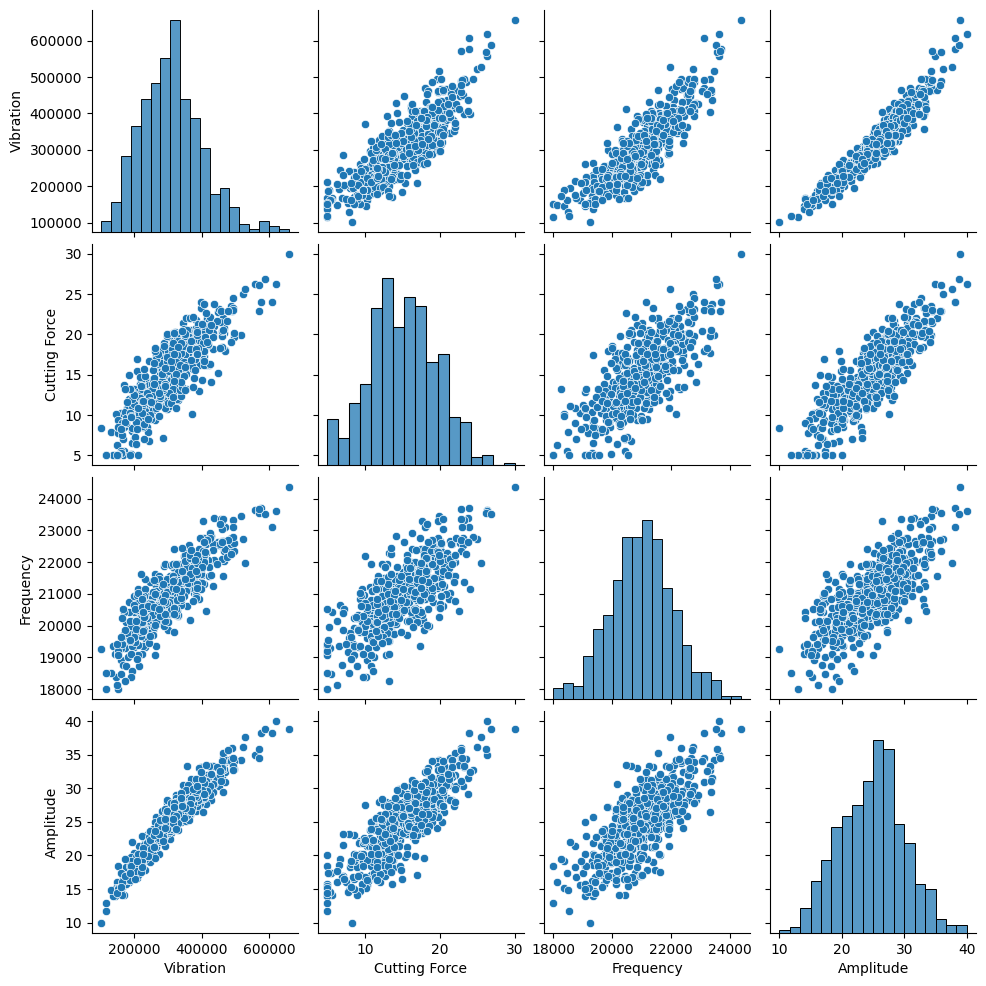

In [3]:
sns.pairplot(df)
plt.show()

In [12]:
from sklearn.preprocessing import StandardScaler

features = [
    "Vibration",
    "Cutting Force",
    "Frequency",
    "Amplitude"
]

X = df[features]

scaler = StandardScaler()
X_scaled = scaler.fit_transform(X)
print(X_scaled)

[[ 0.56126228  0.61221603  0.23293635  0.84984912]
 [-0.91036569 -0.83886539 -1.26071974 -0.62777099]
 [ 0.65612812  1.10172723  0.40715225  0.4760466 ]
 ...
 [-0.51389683  0.71586554 -0.90731566 -0.24705273]
 [-1.62735244 -1.54135595 -1.25236937 -1.83962691]
 [-1.10021581 -1.53962681 -1.89152597 -1.09420043]]


In [5]:
from sklearn.decomposition import PCA

pca = PCA()

X_pca = pca.fit_transform(X_scaled)

print("Explained Variance Ratio:")
print(pca.explained_variance_ratio_)

print("\nCumulative Explained Variance:")
print(pca.explained_variance_ratio_.cumsum())

Explained Variance Ratio:
[0.8769365  0.07293265 0.04525678 0.00487406]

Cumulative Explained Variance:
[0.8769365  0.94986916 0.99512594 1.        ]


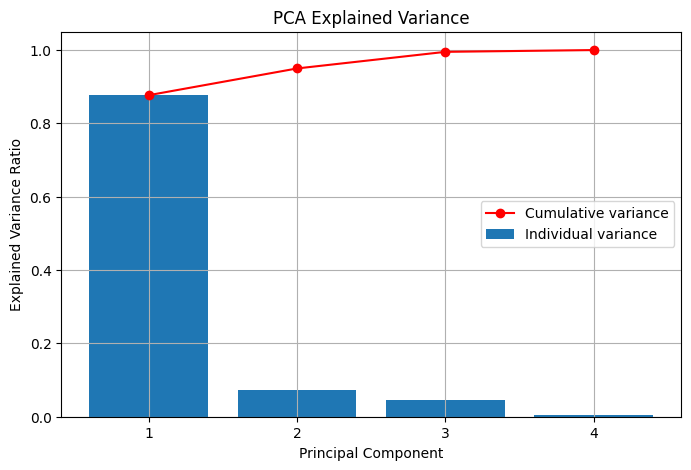

In [6]:
explained_variance = pca.explained_variance_ratio_

plt.figure(figsize=(8, 5))

plt.bar(
    range(1, 5),
    explained_variance,
    label="Individual variance"
)

plt.plot(
    range(1, 5),
    np.cumsum(explained_variance),
    marker="o",
    color="red",
    label="Cumulative variance"
)

plt.xlabel("Principal Component")
plt.ylabel("Explained Variance Ratio")
plt.title("PCA Explained Variance")
plt.xticks(range(1, 5))
plt.legend()
plt.grid()
plt.show()

In [7]:
loadings = pd.DataFrame(
    pca.components_.T,
    columns=["PC1", "PC2", "PC3", "PC4"],
    index=features
)

print(loadings)

                    PC1       PC2       PC3       PC4
Vibration      0.524446  0.047335 -0.356021  0.771988
Cutting Force  0.488413 -0.480621  0.727567  0.033204
Frequency      0.477659  0.805308  0.223680 -0.270717
Amplitude      0.508185 -0.343863 -0.542091 -0.574147


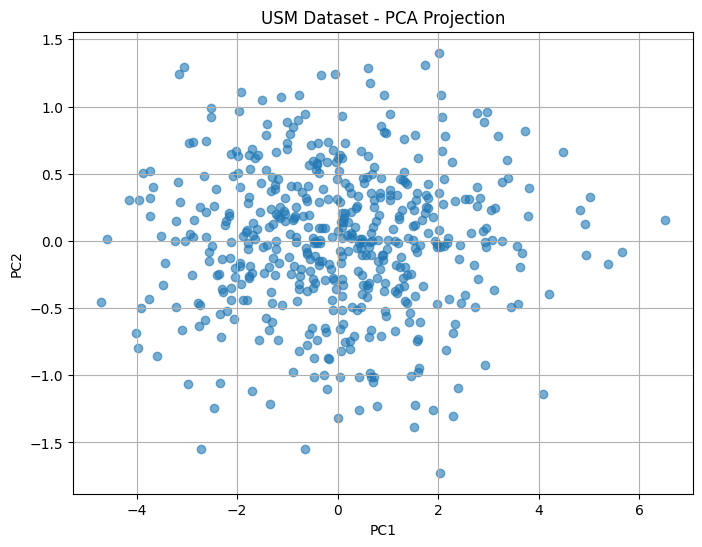

In [8]:
plt.figure(figsize=(8, 6))

plt.scatter(
    X_pca[:, 0],
    X_pca[:, 1],
    alpha=0.6
)

plt.xlabel("PC1")
plt.ylabel("PC2")
plt.title("USM Dataset - PCA Projection")
plt.grid()
plt.show()

In [9]:
cumulative_variance = np.cumsum(
    pca.explained_variance_ratio_
)

n_components = np.argmax(
    cumulative_variance >= 0.95
) + 1

print("Components required:", n_components)

Components required: 3


In [10]:
pca_final = PCA(n_components=n_components)

X_reduced = pca_final.fit_transform(X_scaled)

reduced_df = pd.DataFrame(
    X_reduced,
    columns=[f"PC{i+1}" for i in range(n_components)]
)

print(reduced_df.head())

        PC1       PC2       PC3
0  1.136510 -0.372322 -0.162985
1 -1.808367 -0.439317 -0.227911
2  1.318601 -0.334267  0.400997
3  1.585950  0.357125  0.536062
4 -4.155877  0.303476  0.902329
